
<h1 align="center"> CSE 242 Assignment 2



<h2 align="center"> 3 Questions, 100 pts
    
    Your name: Wajid Ali         Student ID:2252869

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estiamtion (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a)**:

Let $h$ be the probability of heads. For the sequence HHHTT (3 heads, 2 tails), the likelihood is

$$L(h) = P(\mathbf{HHHTT} \mid h) = h^3 (1-h)^2$$

Take the log-likelihood:

$$\log L(h) = 3\log h + 2\log(1-h)$$

Set the derivative to zero:

$$\frac{d}{dh}\log L(h) = \frac{3}{h} - \frac{2}{1-h} = 0$$

$$3(1-h) = 2h \;\Rightarrow\; 3 = 5h \;\Rightarrow\; \hat{h}_{MLE} = \frac{3}{5} = 0.6$$

The second derivative, $-\frac{3}{h^2} - \frac{2}{(1-h)^2}$, is negative, so this is a maximum.

**Solution (b)**:

By Bayes' rule, the posterior is proportional to the likelihood times the prior:

$$p(h \mid \mathbf{HHHTT}) = \frac{P(\mathbf{HHHTT} \mid h)\, p(h)}{P(\mathbf{HHHTT})}$$

The likelihood is $P(\mathbf{HHHTT} \mid h) = h^3(1-h)^2$. The denominator is found by integrating over all values of $h$:

$$P(\mathbf{HHHTT}) = \int_0^1 P(\mathbf{HHHTT} \mid t)\, p(t)\, dt = \int_0^1 t^3 (1-t)^2\, p(t)\, dt$$

Therefore:

$$p(h \mid \mathbf{HHHTT}) = \frac{h^3 (1-h)^2\, p(h)}{\int_0^1 t^3 (1-t)^2\, p(t)\, dt}, \quad h \in [0,1]$$


**If you are not familair with Latex, you may attach a figure/screen-shoot and display the code below.**

In [24]:
from IPython.display import Image
# Replace the figure name
# Image(filename='sample.png') 

# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Reading data using Pandas

In [25]:
# Read the dataset you will be working on
# The dataframe loaded with pandas is named as data

import pandas as pd
data = pd.read_csv('Advertising.csv', index_col=0)  # Modify your data path accordingly.

# Take a look at the first 5 rows
data.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [26]:
data.shape

(200, 4)

### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [27]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.DataFrame'>
(200, 3)


In [28]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.Series'>
(200,)


## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [29]:
################# Your answer for Question 2.1   #################

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
################# Your code above #################

Double check the shape of train and test data:

In [30]:
# default split is 80% for training and 20% for testing
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(160, 3)
(160,)
(40, 3)
(40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [31]:
################# Your answer for Question 2.2   #################
# Name your linear regression model as 'model', so proceeding cells won't run into errors.
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

################# Your code above #################

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.05,0.18,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.908
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [32]:
# Take a look at your model coefficients
import numpy as np
print(np.round(model.intercept_, 4))
print([np.round(val, 4) for val in model.coef_])

2.9079
[np.float64(0.0468), np.float64(0.1785), np.float64(0.0026)]


In [33]:
# Match the feature names with the trained coefficients
list(zip(data.columns[:3].tolist(), model.coef_))

[('TV', np.float64(0.04684310317699042)),
 ('Radio', np.float64(0.17854434380887602)),
 ('Newspaper', np.float64(0.0025861860939890013))]

## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$$

- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

### Your solution for Question 2.3: 
$$\text{Sales} = 2.9079 + 0.0468 \times \text{TV} + 0.1785 \times \text{Radio} + 0.0026 \times \text{Newspaper}$$

**Interpretation of TV (β₁ = 0.0468):** 
Holding Radio and Newspaper spending fixed, every extra $1,000 spent on TV advertising is associated with an average increase of about 0.0468 thousand items sold (roughly 47 items). This is an association, not proof that TV ads cause the increase.


### Making predictions

In [34]:
# make predictions on the testing set
y_pred = model.predict(X_test)
# Print the test accuracy score from your trained linear regression model
model.score(X_test,y_test)

0.8927605914615384

## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [35]:
from sklearn import metrics
################# Your answer for Question 2.4   #################
import numpy as np
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
print(rmse)
################# Your code above #################

1.4113417558581587


## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

In [36]:
################# Your answer for Question 2.5   #################
X2 = data[['TV', 'Radio']]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=1)  # same random_state as 2.1
model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred = model2.predict(X2_test)
rmse2 = np.sqrt(metrics.mean_squared_error(y2_test, y2_pred))
print("RMSE with Newspaper:", rmse)
print("RMSE without Newspaper:", rmse2)

################# Your code above #################

RMSE with Newspaper: 1.4113417558581587
RMSE without Newspaper: 1.398292489077775


### Your observations:

RMSE with Newspaper is 1.4113 and without Newspaper is 1.3983. Removing Newspaper lowers the RMSE slightly, so the model predicts a little better without it. This means Newspaper does not help the prediction and adds a bit of noise. This agrees with its coefficient (0.0026), which is close to zero. TV and Radio carry almost all of the predictive power.


# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [37]:
# import libraries
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; 
sns.set()

In [38]:
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

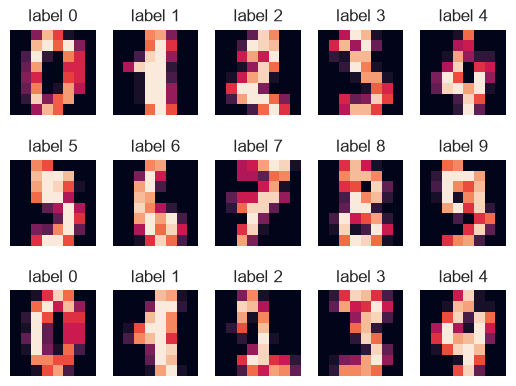

In [39]:
# A help function to display images with labels
def display_digits(imgs):
    h = 3
    w = 5
    fig, axes = plt.subplots(h, w)
    for i in range(h):
        for j in range(w):
            if imgs.shape[1] == 64:
                axes[i, j].imshow(imgs[i * w + j].reshape(8, 8))
            else:
                axes[i, j].imshow(imgs[i * w + j])
            axes[i, j].axis('off')
            axes[i, j].set_title(f'label {data_digit.target[i * w + j]}')
# Take a look at a few examples
display_digits(data_digit.images)

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [40]:
from sklearn.decomposition import PCA

################# Your answer for Question 3.1   #################

# name the transformed (dimension reduced) feature as projected
projected = PCA(n_components=2).fit_transform(data_digit.data)################# Complete the code above #################


# The code below checks whether the feature dimension 64 is reduced to 2.
print(data_digit.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

<Figure size 1800x800 with 0 Axes>

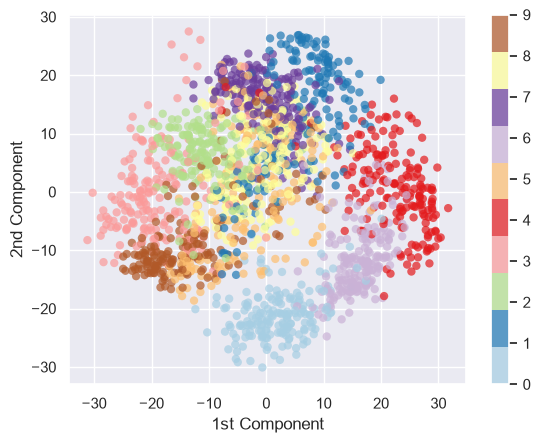

<Figure size 1800x800 with 0 Axes>

In [41]:
plt.scatter(projected[:, 0], projected[:, 1],
            c=data_digit.target, edgecolor='none', alpha=0.7,
            cmap=plt.get_cmap('Paired', 10))
plt.xlabel('1st Component')
plt.ylabel('2nd Component')
plt.colorbar()
plt.figure(figsize=(18, 8))

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

[1.48905936e-01 1.36187712e-01 1.17945938e-01 8.40997942e-02
 5.78241466e-02 4.91691032e-02 4.31598701e-02 3.66137258e-02
 3.35324810e-02 3.07880621e-02 2.37234084e-02 2.27269657e-02
 1.82186331e-02 1.77385494e-02 1.46710109e-02 1.40971560e-02
 1.31858920e-02 1.24813782e-02 1.01771796e-02 9.05617439e-03
 8.89538461e-03 7.97123157e-03 7.67493255e-03 7.22903569e-03
 6.95888851e-03 5.96081458e-03 5.75614688e-03 5.15157582e-03
 4.89539777e-03 4.28887968e-03 3.73606048e-03 3.53274223e-03
 3.36683986e-03 3.28029851e-03 3.08320884e-03 2.93778629e-03
 2.56588609e-03 2.27742397e-03 2.22277922e-03 2.11430393e-03
 1.89909062e-03 1.58652907e-03 1.51159934e-03 1.40578764e-03
 1.16622290e-03 1.07492521e-03 9.64053065e-04 7.74630271e-04
 5.57211553e-04 4.04330693e-04 2.09916327e-04 8.24797098e-05
 5.25149980e-05 5.05243719e-05 3.29961363e-05 1.24365445e-05
 7.04827911e-06 3.01432139e-06 1.06230800e-06 5.50074587e-07
 3.42905702e-07 8.47114483e-19 5.53536763e-19 0.00000000e+00]


Text(0, 0.5, 'Ratio of explained variance')

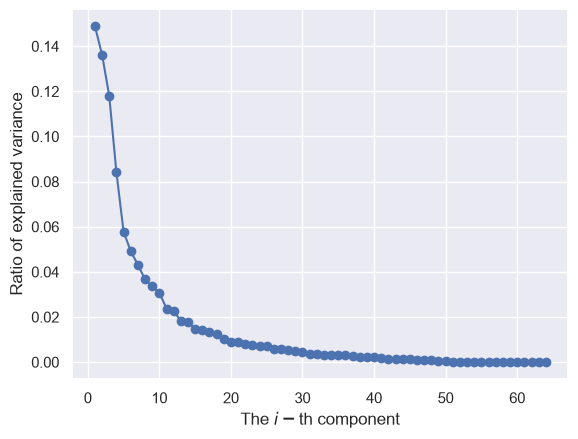

In [42]:
################# Your answer for Question 3.2   #################


pca_full = PCA().fit(data_digit.data)
ratios = pca_full.explained_variance_ratio_
print(ratios)
plt.plot(range(1, len(ratios) + 1), ratios, marker='o')
plt.xlabel('The $i-$th component')
plt.ylabel('Ratio of explained variance')
################# Complete the code above #################

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

Text(0.5, 0.98, 'The eigen vector of each component')

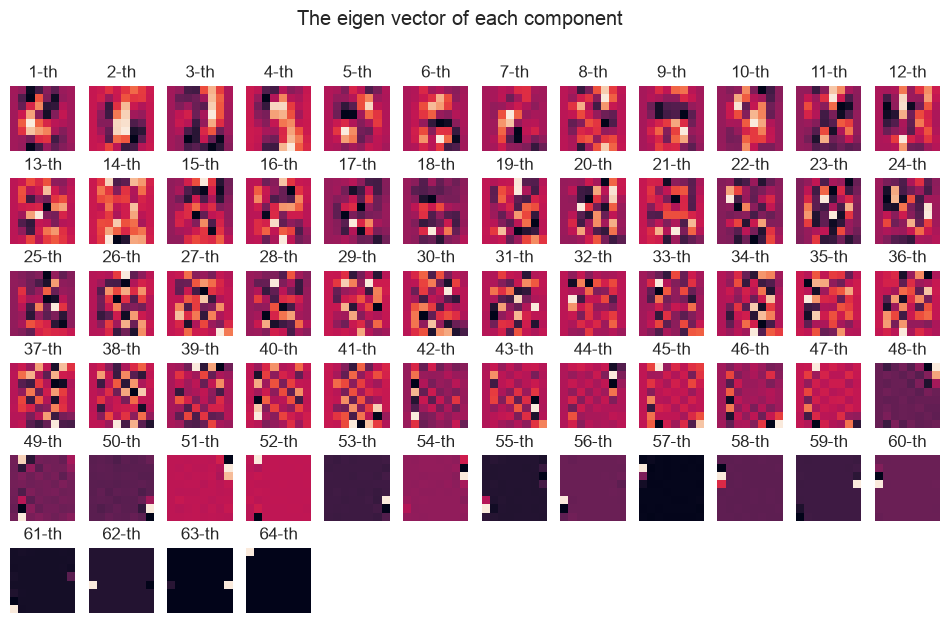

In [43]:
# Default # of components is the dimension of feature space 
pca = PCA()
pca.fit(data_digit.data)
h = 6
w = 12
fig, axes = plt.subplots(h, w)
fig.set_size_inches(12, 7)
for i in range(h):
    for j in range(w):
        idx = i * w + j
        if idx > 63:
            axes[i, j].axis('off')
        else:
            axes[i, j].imshow(pca.components_[idx].reshape(8, 8))
            axes[i, j].axis('off')
            axes[i, j].set_title(f'{idx + 1}-th')
fig.suptitle('The eigen vector of each component')

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

### Your solutions for Question 3.3: 
The first few eigenvectors show larger, more organized patterns, so they capture the main differences between digits. The middle ones look like random speckle, so they capture only small details or noise. The last ones are almost flat, with only one or two bright pixels, so they carry almost no information. This matches the explained variance plot, where the first few components carry most of the variance.

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

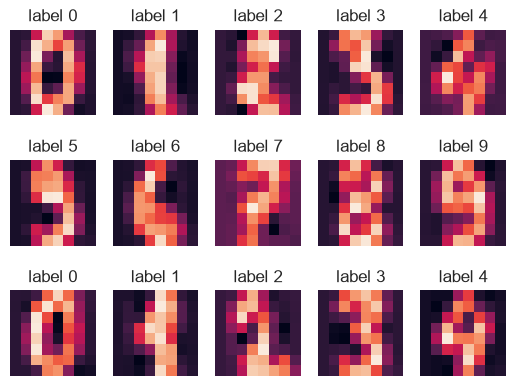

In [44]:
# Use pca from sklearn to fit on the feature space
pca_08 = PCA(0.8).fit(data_digit.data)

# Reconstruct 
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)

# Display the reconstructed images (with a much lower dimension)
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

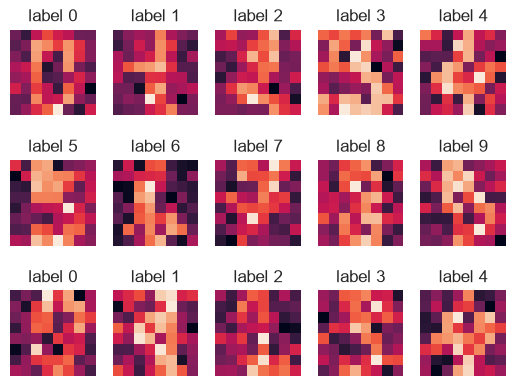

In [45]:
# Apply random noise on clean images
noisy_imgs = np.random.normal(data_digit.data, 5)
# Display the noisy images
display_digits(noisy_imgs)

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

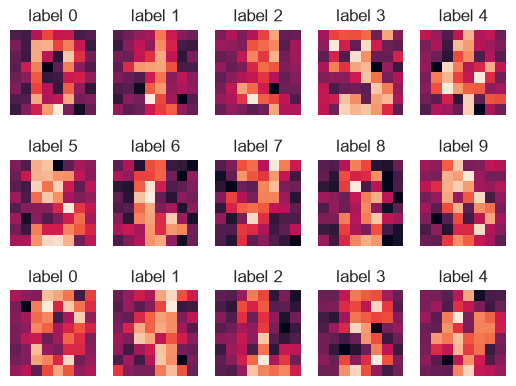

In [46]:
################# Your answer for Question 3.4   #################



# name the reconstructed images from noisy images as 'reconstructed_noise'
pca_noise = PCA(0.8).fit(noisy_imgs)
reconstructed_noise = pca_noise.inverse_transform(pca_noise.transform(noisy_imgs))
# Display the reconstructed images
display_digits(reconstructed_noise) 
################# Complete the code above #################


### Your written answers for Question 3.4:
PCA mitigates the noise, but only partly here. The digit images have real structure, so their information is concentrated in a few top principal components. Random noise is spread roughly evenly across all 64 directions, so each direction gets only a small part of it. Keeping only the components that explain 80% of the variance removes some of the noise, and the reconstructed images are slightly smoother than the noisy ones. However, the noise here is strong, so 80% of the variance still includes many noise-dominated components, and the digits are still hard to recognize. Keeping fewer components (a lower variance threshold) would remove more noise, but would also lose more of the digit detail.


I used Claude (Anthropic) for help with this assignment.